In [ ]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from PIL import Image

from sklearn.model_selection import train_test_split
from xgboost import XGBRegressor



In [2]:
PROJECT_ROOT = Path.cwd()
DATA_DIR = PROJECT_ROOT / "competitions" / "count-coins-and-faces" / "count-coins-and-faces"
TRAIN_DIR = DATA_DIR / "train"
TEST_DIR = DATA_DIR / "test"
TRAIN_CSV = DATA_DIR / "train.csv"
TEST_CSV = DATA_DIR / "test.csv"

RANDOM_SEED = 1488

In [3]:
train_df = pd.read_csv(TRAIN_CSV)
print(f"Total training samples: {len(train_df)}")
print(f"Types: {train_df['type'].value_counts().to_dict()}")

coins_df = train_df[train_df["type"] == "coins"].copy()
coins_df = coins_df.reset_index(drop=True)
print(f"Coin images: {len(coins_df)}")

Total training samples: 3584
Types: {'faces': 2861, 'coins': 723}
Coin images: 723


In [4]:
print("=== Coin Count Statistics ===")
coins_df["count"].describe()

=== Coin Count Statistics ===


count    723.000000
mean       5.255878
std        7.834300
min        1.000000
25%        1.000000
50%        2.000000
75%        6.000000
max      102.000000
Name: count, dtype: float64

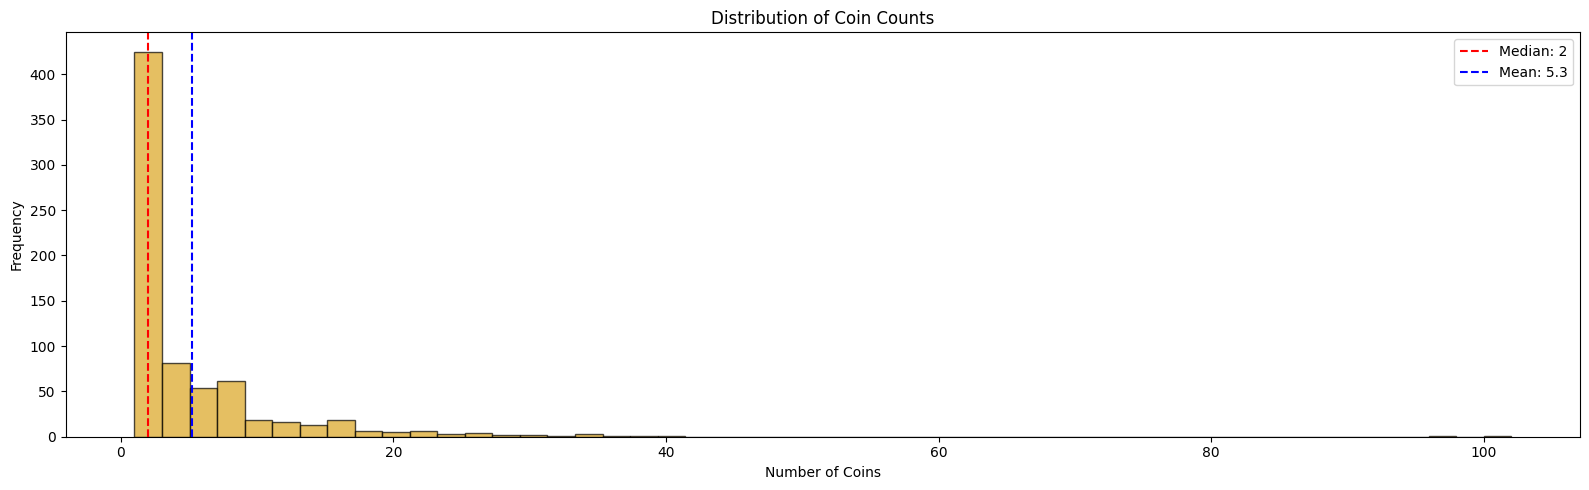

In [5]:



plt.subplots(1, 1, figsize=(16, 5))
plt.hist(coins_df["count"], bins=50, edgecolor="black", alpha=0.7, color="goldenrod")
plt.xlabel("Number of Coins")
plt.ylabel("Frequency")
plt.title("Distribution of Coin Counts")
plt.axvline(coins_df["count"].median(), color="red", linestyle="--", label=f'Median: {coins_df["count"].median():.0f}')
plt.axvline(coins_df["count"].mean(), color="blue", linestyle="--", label=f'Mean: {coins_df["count"].mean():.1f}')
plt.legend()
plt.tight_layout()
plt.show()

In [101]:
def mcrmse(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)

    if y_true.shape != y_pred.shape:
        raise ValueError(f"Shape mismatch: y_true={y_true.shape}, y_pred={y_pred.shape}")

    col_rmse = np.sqrt(np.mean((y_true - y_pred) ** 2, axis=0))
    return float(np.mean(col_rmse))

# Select Test Images


We pick a few images with varying coin counts to test our detection algorithms:
- **Low count** (1-3 coins) - should be easiest to detect
- **Medium count** (4-7 coins) - around the median

In [6]:
low_count = coins_df[coins_df["count"].between(1, 3)]
print(len(low_count))
low_count = low_count.sample(4, random_state=RANDOM_SEED)

medium_count = coins_df[coins_df["count"].between(4, 7)]
print(len(medium_count))
medium_count = medium_count.sample(4, random_state=RANDOM_SEED)

425
135


In [7]:
test_samples = pd.concat([low_count, medium_count]).sort_values("count").reset_index(drop=True)
test_samples

,image_id,type,count
0,53fcbdba54514c736ae6ac46fc55325d66bb33c9,coins,1
1,b0813e38f7aebda46f75eb0f43a56c1edc8e9323,coins,1
2,1ea4bf50f900d2eb162ff3a80347bc0c92214ac3,coins,1
3,e6aea6628396d9a09a2e2e5df74da7e9341bee23,coins,2
4,b380eba52fd4402e6b8e344a01474f182d3fa4b8,coins,4
5,5136dc4cb00e1432866b53a1270f8f600bf0b4c1,coins,4
6,c6304033f9e2d4695ee047845e7818a411463d43,coins,6
7,cd1dd8e7ccbf3a917894c1dac65674bfd84498fa,coins,6


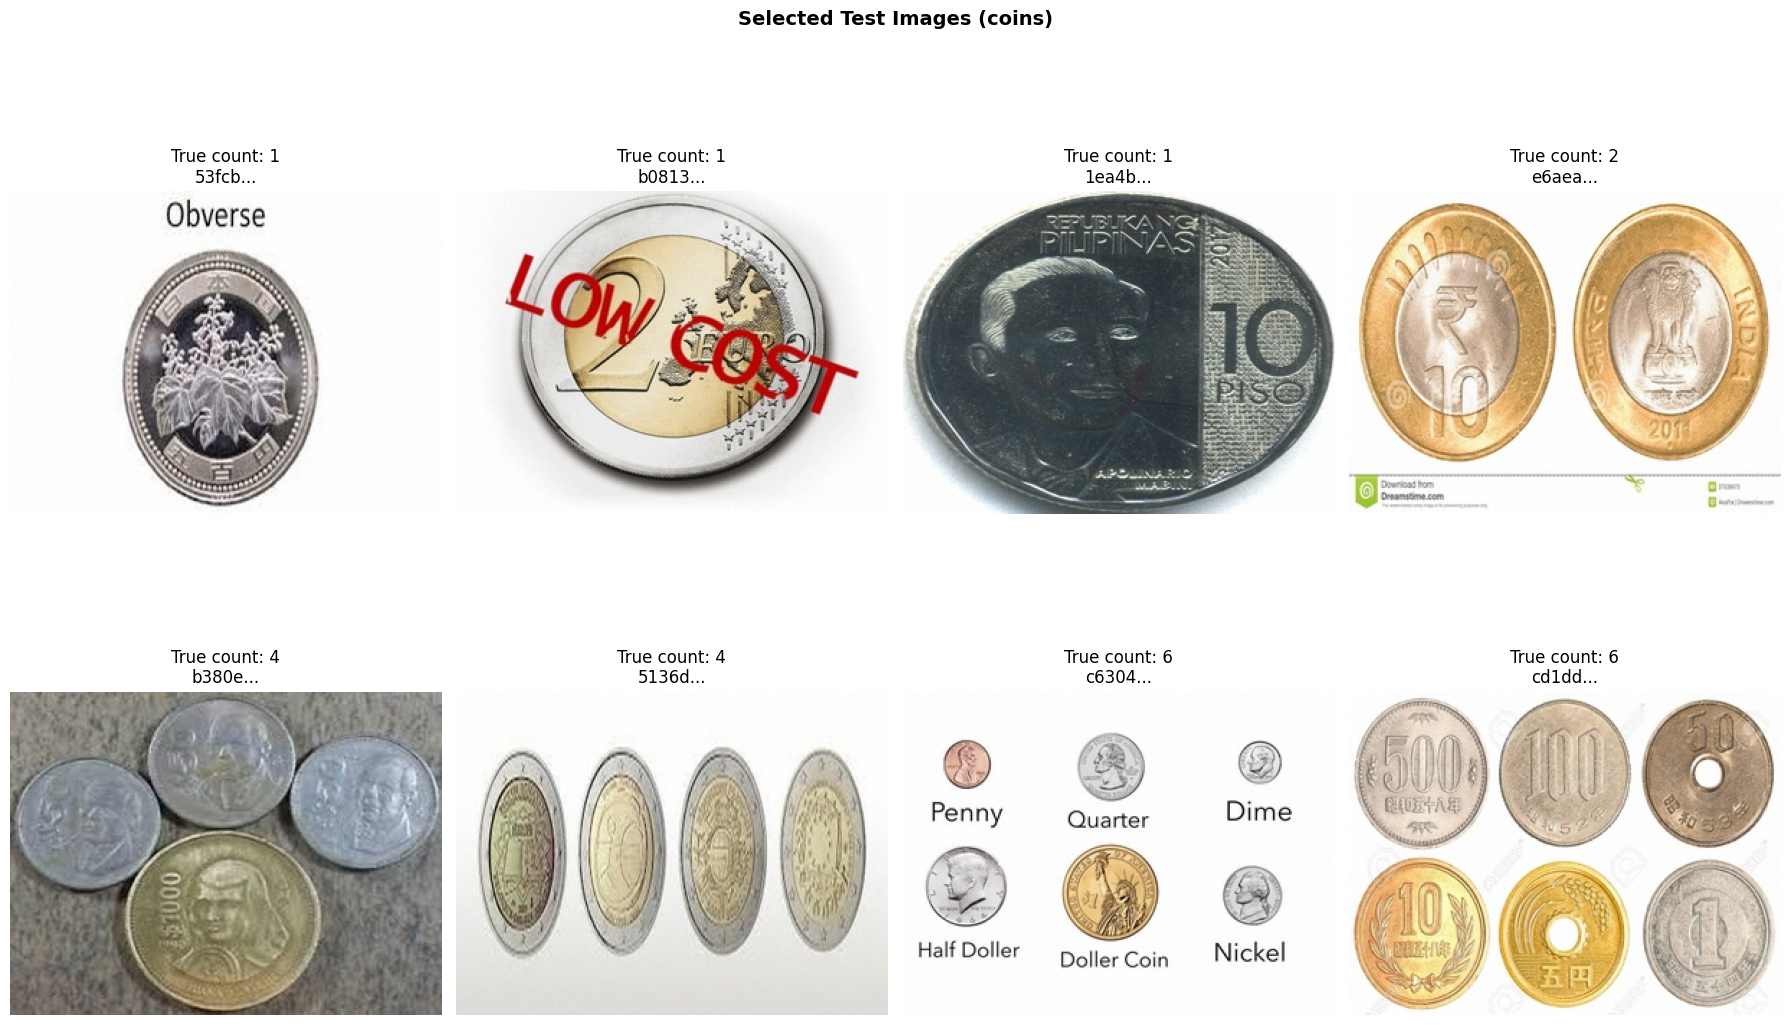

In [8]:
n_images = len(test_samples)
fig, axes = plt.subplots(2, 4, figsize=(18, 12))
axes = axes.flatten()

for idx, row in test_samples.iterrows():
    img_path = TRAIN_DIR / f"{row['image_id']}.jpg"
    img = cv2.imread(str(img_path))
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    axes[idx].imshow(img_rgb)
    axes[idx].set_title(f"True count: {row['count']}\n{row['image_id'][:5]}...")
    axes[idx].axis("off")

plt.suptitle("Selected Test Images (coins)", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

In [238]:
test_samples

,image_id,type,count
0,53fcbdba54514c736ae6ac46fc55325d66bb33c9,coins,1
1,b0813e38f7aebda46f75eb0f43a56c1edc8e9323,coins,1
2,1ea4bf50f900d2eb162ff3a80347bc0c92214ac3,coins,1
3,e6aea6628396d9a09a2e2e5df74da7e9341bee23,coins,2
4,b380eba52fd4402e6b8e344a01474f182d3fa4b8,coins,4
5,5136dc4cb00e1432866b53a1270f8f600bf0b4c1,coins,4
6,c6304033f9e2d4695ee047845e7818a411463d43,coins,6
7,cd1dd8e7ccbf3a917894c1dac65674bfd84498fa,coins,6


## Test detection

In [127]:
def plots_baseline(original_img, thresh, image_copy, num):
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))

    axes[0].imshow(cv2.cvtColor(original_img, cv2.COLOR_BGR2RGB))
    axes[0].set_title("Original")
    axes[0].axis("off")

    axes[1].imshow(thresh, cmap="gray")
    axes[1].set_title("Threshold")
    axes[1].axis("off")

    axes[2].imshow(cv2.cvtColor(image_copy, cv2.COLOR_BGR2RGB))
    axes[2].set_title(f"Contours (count={num })")
    axes[2].axis("off")

    plt.tight_layout()
    plt.show()

In [9]:
def preprocess(image_path, ksize=(5, 5), sigma=0):
    img = cv2.imread(str(image_path))
    if img is None:
        raise ValueError(f"Could not read image: {image_path}")

    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    blurred = cv2.GaussianBlur(gray, ksize, sigma)
    return img, blurred


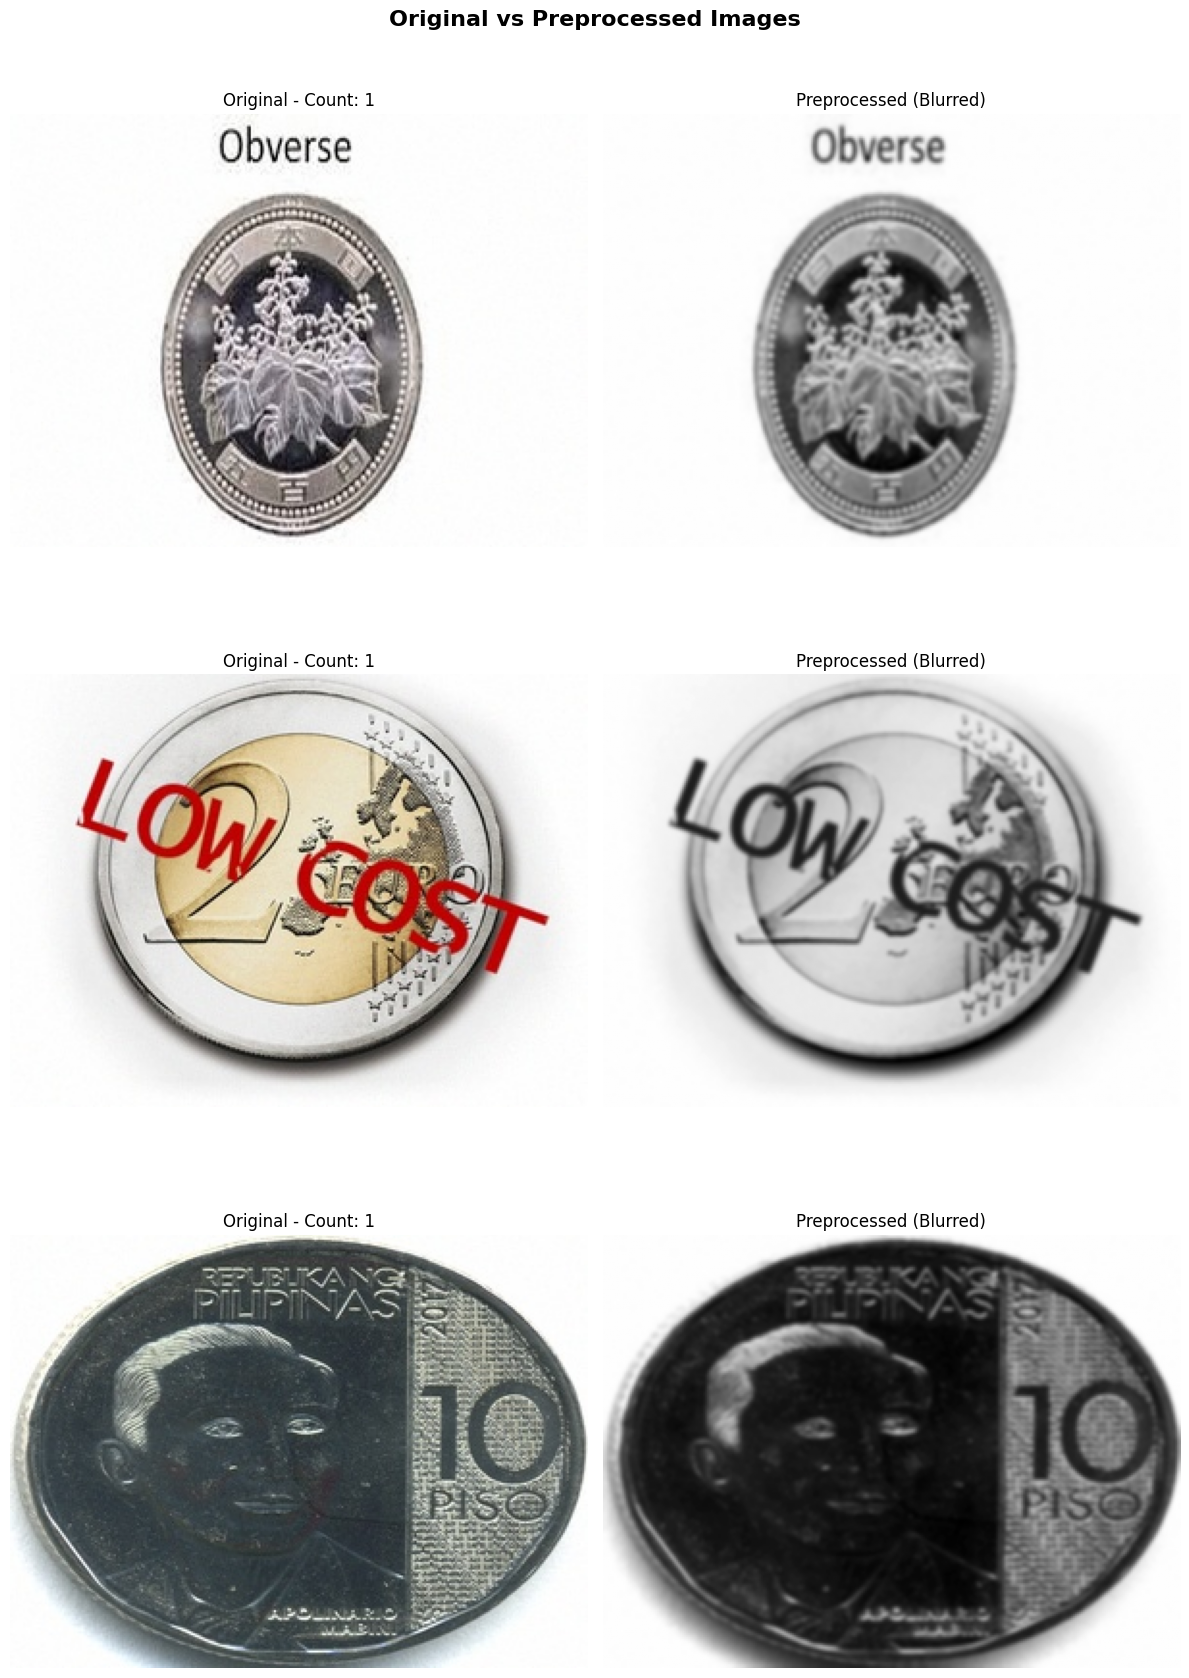

In [99]:
subset = test_samples.head(3)
n_len = len(subset)
fig, axes = plt.subplots(n_len, 2, figsize=(12, 6 * n_len))

for idx, row in subset.iterrows():
    img_path = TRAIN_DIR / f"{row['image_id']}.jpg"
    original_img, preprocessed_img = preprocess(img_path, ksize=(5, 5), sigma=0)

    axes[idx, 0].imshow(cv2.cvtColor(original_img, cv2.COLOR_BGR2RGB))
    axes[idx, 0].set_title(f"Original - Count: {row['count']}")
    axes[idx, 0].axis("off")

    axes[idx, 1].imshow(preprocessed_img, cmap="gray")
    axes[idx, 1].set_title("Preprocessed (Blurred)")
    axes[idx, 1].axis("off")
plt.suptitle("Original vs Preprocessed Images", fontsize=16, fontweight="bold")
plt.tight_layout()  
plt.show()

# Coin Detection Methods

Three classical CV approaches:
1. **Hough Circle Transform**
2. **Contour Detection**
3. **Blob Detection**

## Contour

In [91]:

def count_coins_baseline(image_path, min_area = 1000, max_area = 100000):
    original_img, preprocessed_img = preprocess(image_path, ksize=(7, 7), sigma=3)
    _, thresh = cv2.threshold(preprocessed_img, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    

    contours, _ = cv2.findContours(thresh, cv2.RETR_TREE, cv2.CHAIN_APPROX_SIMPLE)
    contours = sorted(contours, key=cv2.contourArea, reverse=True)

    coin_contours = [c for c in contours if min_area < cv2.contourArea(c) < max_area]

    image_copy = original_img.copy()
    cv2.drawContours(image_copy, coin_contours, -1, (0, 255, 0), 2)

    return len(coin_contours), original_img, thresh, image_copy


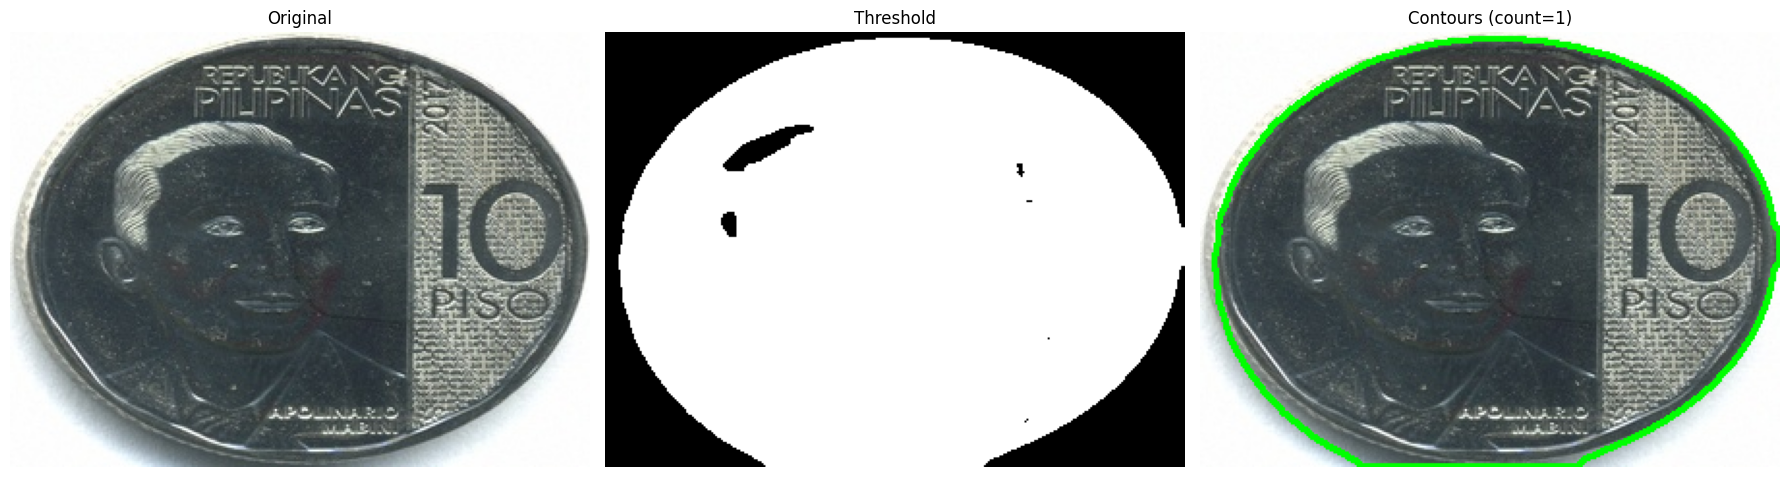

In [94]:
image_id = "1ea4bf50f900d2eb162ff3a80347bc0c92214ac3"
img_path = TRAIN_DIR / f"{image_id}.jpg"
num, original_img, thresh, image_copy = count_coins_baseline(img_path)
plots_baseline(original_img, thresh, image_copy, num)

In [126]:
# for _, row in test_samples.iterrows():
#     image_id = row["image_id"]
#     true_count = row.get("count", None)  

#     img_path = TRAIN_DIR / f"{image_id}.jpg"
#     num, original_img, thresh, image_copy = count_coins_baseline(img_path)

#     print(f"image_id: {image_id} | true: {true_count} | pred: {num}")
#     plots_baseline(original_img, thresh, image_copy, num)


## Blob Detection 


In [136]:
def detect_coins_blobs_with_preprocess_cv2(
    image_path,
    min_area=200,
    max_area=20000,
    min_circularity=0.5,
    min_inertia_ratio=0.2,
    min_convexity=0.7,
    min_threshold=10,
    max_threshold=220,
    threshold_step=10,
    min_dist_between_blobs=5,
    filter_by_color=False,
    blob_color=255,
):
    original_img, preprocessed_img = preprocess(image_path, ksize=(5, 5), sigma=0)

    p = cv2.SimpleBlobDetector_Params()
    p.filterByArea = True
    p.minArea = float(min_area)
    p.maxArea = float(max_area)

    p.filterByCircularity = True
    p.minCircularity = float(min_circularity)

    p.filterByInertia = True
    p.minInertiaRatio = float(min_inertia_ratio)

    p.filterByConvexity = True
    p.minConvexity = float(min_convexity)

    p.minThreshold = float(min_threshold)
    p.maxThreshold = float(max_threshold)
    p.thresholdStep = float(threshold_step)
    p.minDistBetweenBlobs = float(min_dist_between_blobs)

    p.filterByColor = bool(filter_by_color)
    if p.filterByColor:
        p.blobColor = int(blob_color)

    detector = cv2.SimpleBlobDetector_create(p)
    keypoints = detector.detect(preprocessed_img)

    pred_count = len(keypoints)
    img_rgb = cv2.cvtColor(original_img, cv2.COLOR_BGR2RGB)
    vis_bgr = cv2.drawKeypoints(original_img, keypoints, None, (0, 255, 0), cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
    vis_rgb = cv2.cvtColor(vis_bgr, cv2.COLOR_BGR2RGB)
    return img_rgb, preprocessed_img, keypoints, pred_count, vis_rgb


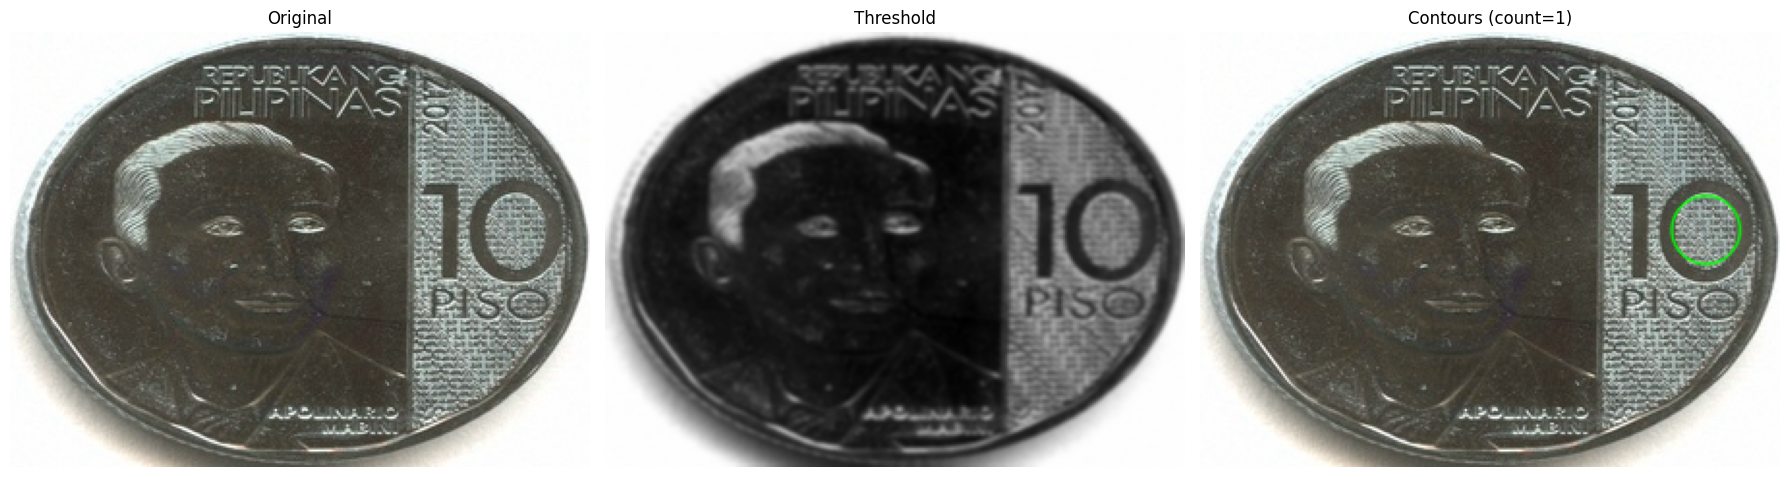

In [135]:
image_id = "1ea4bf50f900d2eb162ff3a80347bc0c92214ac3"
img_path = TRAIN_DIR / f"{image_id}.jpg"
img_rgb, gray_proc, keypoints, pred_count, vis_rgb = detect_coins_blobs_with_preprocess_cv2(img_path)
plots_baseline(img_rgb, gray_proc, vis_rgb, pred_count)

In [109]:
# def evaluate_params_cv(df_subset, params, n_splits=5, seed=1488):
#     df_subset = df_subset.copy().reset_index(drop=True)
#     strat_bins = make_strat_bins(df_subset["count"])

#     skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
#     fold_scores = []

#     for _, val_idx in skf.split(df_subset, strat_bins):
#         val_df = df_subset.iloc[val_idx]

#         y_true = val_df["count"].to_numpy(dtype=float)
#         y_pred = []

#         for _, row in val_df.iterrows():
#             img_path = TRAIN_DIR / f"{row['image_id']}.jpg"
#             pred_count = predict_count_for_image(img_path, **params)
#             y_pred.append(pred_count)

#         fold_score = mcrmse(y_true, np.asarray(y_pred, dtype=float))
#         fold_scores.append(fold_score)

#     return {
#         "cv_mcrmse": float(np.mean(fold_scores)),
#         "fold_scores": fold_scores,
#     }

## Hough

In [110]:
def count_coins_hough(
    image_path,
    dp=1.2,
    min_dist=24,
    param1=120,
    param2=22,
    min_radius=8,
    max_radius=90,
    blur_ksize=9,
    blur_sigma=2,
):
    blur_ksize = int(blur_ksize)
    if blur_ksize % 2 == 0:
        blur_ksize += 1

    original_img, preprocessed_img = preprocess(
        image_path,
        ksize=(blur_ksize, blur_ksize),
        sigma=float(blur_sigma),
    )

    circles = cv2.HoughCircles(
        preprocessed_img,
        cv2.HOUGH_GRADIENT,
        dp=float(dp),
        minDist=float(min_dist),
        param1=float(param1),
        param2=float(param2),
        minRadius=int(min_radius),
        maxRadius=int(max_radius),
    )

    image_copy = original_img.copy()
    pred_count = 0

    if circles is not None:
        circles = np.round(circles[0, :]).astype(int)
        pred_count = len(circles)
        for x, y, r in circles:
            cv2.circle(image_copy, (x, y), r, (0, 255, 0), 2)
            cv2.circle(image_copy, (x, y), 2, (255, 0, 0), 3)

    return pred_count, original_img, preprocessed_img, image_copy


In [114]:
hough_params = {
    "dp": 1.2,
    "min_dist": 90,      
    "param2": 55,     
    "min_radius": 70,    
    "max_radius": 160,
    "blur_ksize": 7,
    "blur_sigma": 3,
}


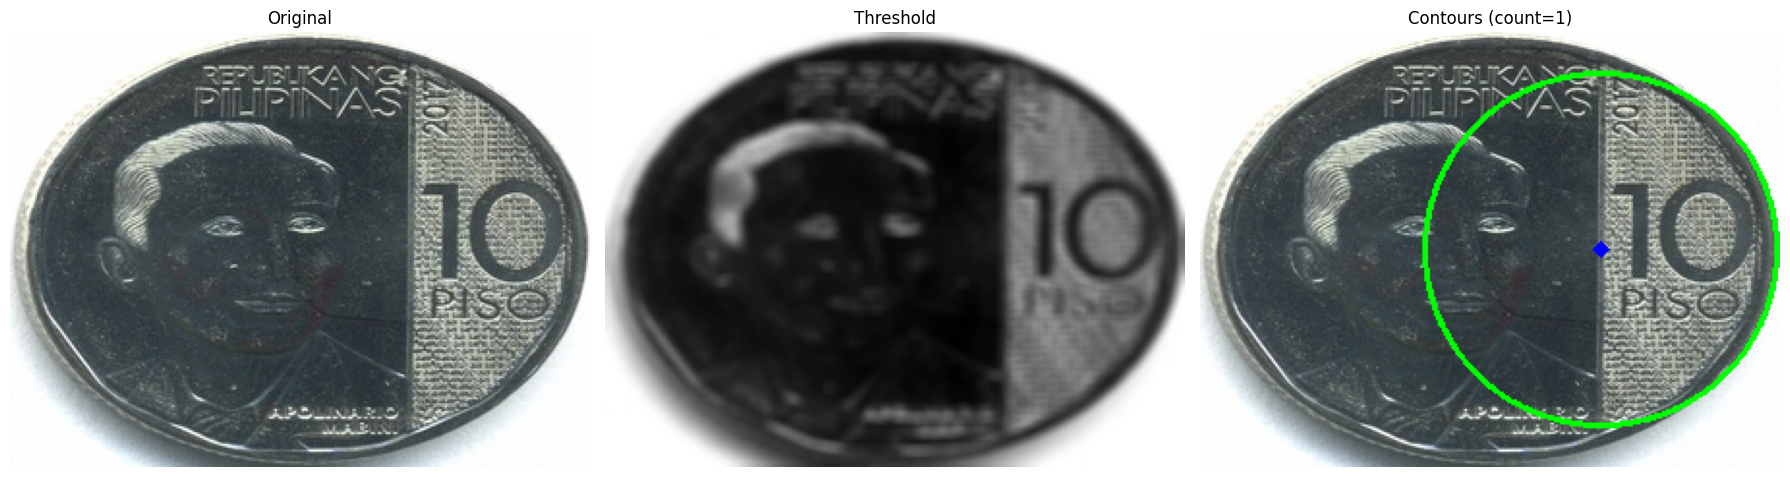

In [115]:
image_id = "1ea4bf50f900d2eb162ff3a80347bc0c92214ac3"
img_path = TRAIN_DIR / f"{image_id}.jpg"
num, original_img, preprocessed_img, image_copy = count_coins_hough(img_path, **hough_params)
plots_baseline(original_img, preprocessed_img, image_copy, num)


### Show case 

In [128]:
def _run_algorithm_with_visuals(image_path, algorithm, params=None):
    params = params or {}

    if algorithm == "hough_circles":
        pred_count, original_img, preprocessed_img, image_copy = count_coins_hough(
            image_path, **params
        )
        return int(pred_count), cv2.cvtColor(original_img, cv2.COLOR_BGR2RGB), cv2.cvtColor(image_copy, cv2.COLOR_BGR2RGB)

    if algorithm == "baseline_contours":
        pred_count, original_img, thresh, image_copy = count_coins_baseline(
            image_path, **params
        )
        return int(pred_count), cv2.cvtColor(original_img, cv2.COLOR_BGR2RGB), cv2.cvtColor(image_copy, cv2.COLOR_BGR2RGB)

    if algorithm == "cv2_blob":
        img_rgb, preprocessed_img, keypoints, pred_count, vis_rgb = detect_coins_blobs_with_preprocess_cv2(
            image_path, **params
        )
        return int(pred_count), img_rgb, vis_rgb

    raise ValueError(f"Unknown algorithm: {algorithm}")

In [ ]:
def predict_and_plot_image(
    image_path,
    algorithms,
    params_by_algorithm=None,
    image_id=None,
    true_count=None,
):
    params_by_algorithm = params_by_algorithm or {}
    image_id = image_id if image_id is not None else Path(image_path).stem

    results = []
    original_rgb = None

    for algo in algorithms:
        algo_params = params_by_algorithm.get(algo, {})
        pred, orig_rgb, vis_rgb = _run_algorithm_with_visuals(
            image_path=image_path,
            algorithm=algo,
            params=algo_params,  
        )
        if original_rgb is None:
            original_rgb = orig_rgb
        results.append({"algorithm": algo, "pred": pred, "vis_rgb": vis_rgb})

    row = {"image_id": image_id}
    if true_count is not None:
        row["true_count"] = int(true_count)
    for r in results:
        row[f"pred_{r['algorithm']}"] = int(r["pred"])
    row_df = pd.DataFrame([row])

    n_cols = 1 + len(results)
    fig, axes = plt.subplots(1, n_cols, figsize=(5 * n_cols, 5))
    if n_cols == 1:
        axes = [axes]

    title0 = f"Original\n{image_id}"
    if true_count is not None:
        title0 += f"\ntrue={int(true_count)}"
    axes[0].imshow(original_rgb)
    axes[0].set_title(title0)
    axes[0].axis("off")

    for i, r in enumerate(results, start=1):
        axes[i].imshow(r["vis_rgb"])
        axes[i].set_title(f"{r['algorithm']}\ncount={r['pred']}")
        axes[i].axis("off")

    plt.tight_layout()
    plt.show()

    return row_df

In [130]:
def run_in_loop(
    df,
    images_dir,
    algorithms,
    params_by_algorithm=None,
    image_id_col="image_id",
    true_count_col="count",
):
    rows = []
    for _, r in df.iterrows():
        image_id = r[image_id_col]
        image_path = Path(images_dir) / f"{image_id}.jpg"
        true_count = r[true_count_col] if true_count_col in df.columns else None

        one_row = predict_and_plot_image(
            image_path=image_path,
            algorithms=algorithms,
            params_by_algorithm=params_by_algorithm,
            image_id=image_id,
            true_count=true_count,
        )
        rows.append(one_row.iloc[0].to_dict())

    return pd.DataFrame(rows)

In [117]:
def _predict_with_algorithm(image_path, algorithm, params=None):
    params = params or {}

    if algorithm == "hough_circles":
        pred_count, *_ = count_coins_hough(image_path, **params)
        return int(pred_count)

    if algorithm == "baseline_contours":
        pred_count, *_ = count_coins_baseline(image_path, **params)
        return int(pred_count)

    if algorithm == "cv2_blob":
        _, _, _, pred_count, _ = detect_coins_blobs_with_preprocess_cv2(image_path, **params)
        return int(pred_count)

    raise ValueError(f"Unknown algorithm: {algorithm}")

In [131]:
algos = ["hough_circles", "baseline_contours", "cv2_blob"]
params_map = {
    "hough_circles": hough_params,
    "baseline_contours": None,
    "cv2_blob": None,
}

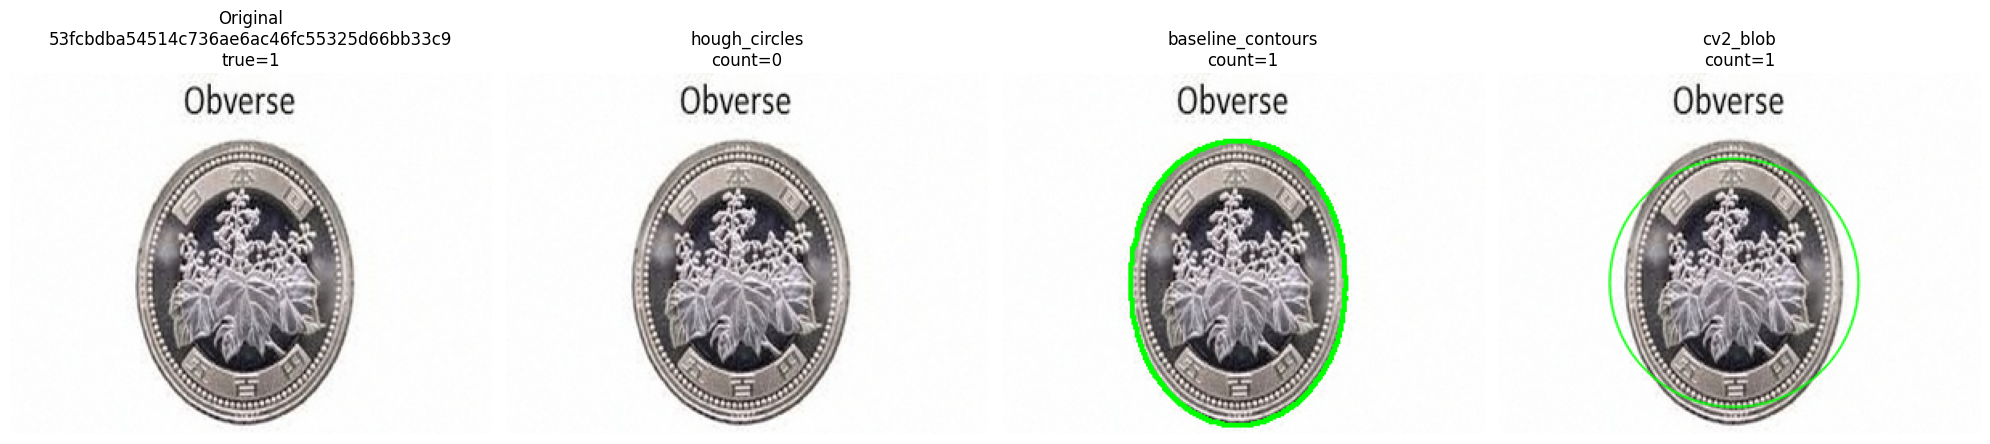

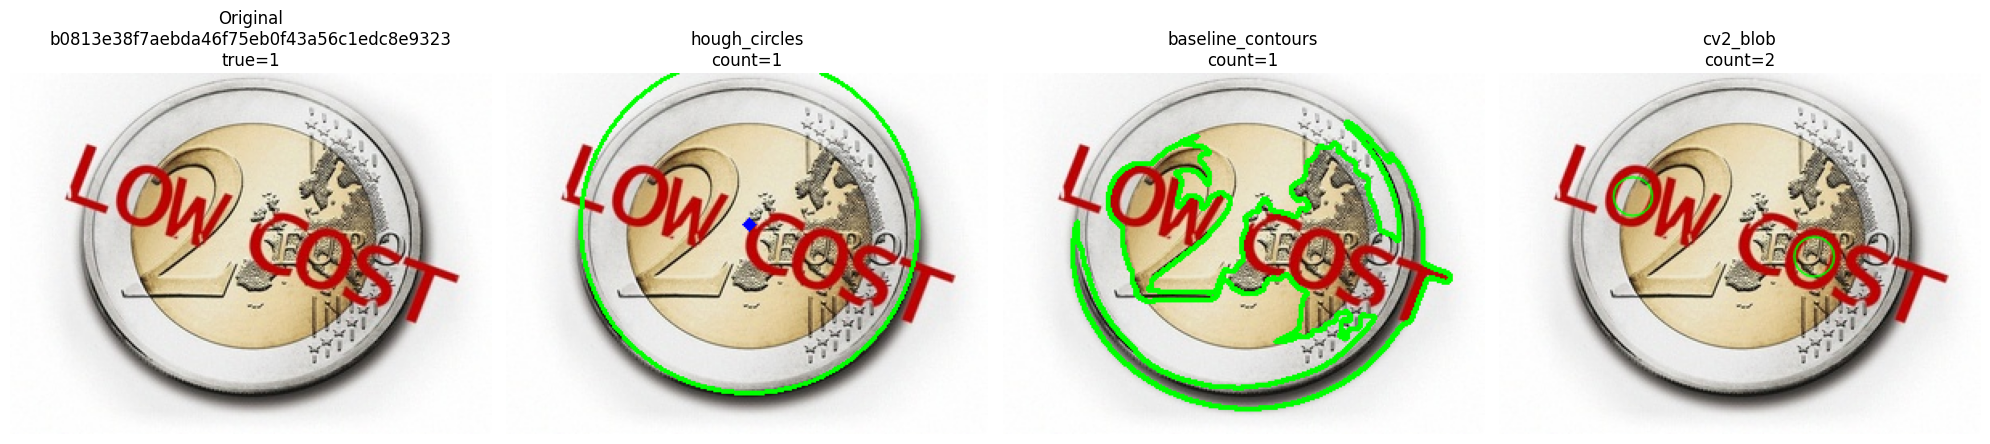

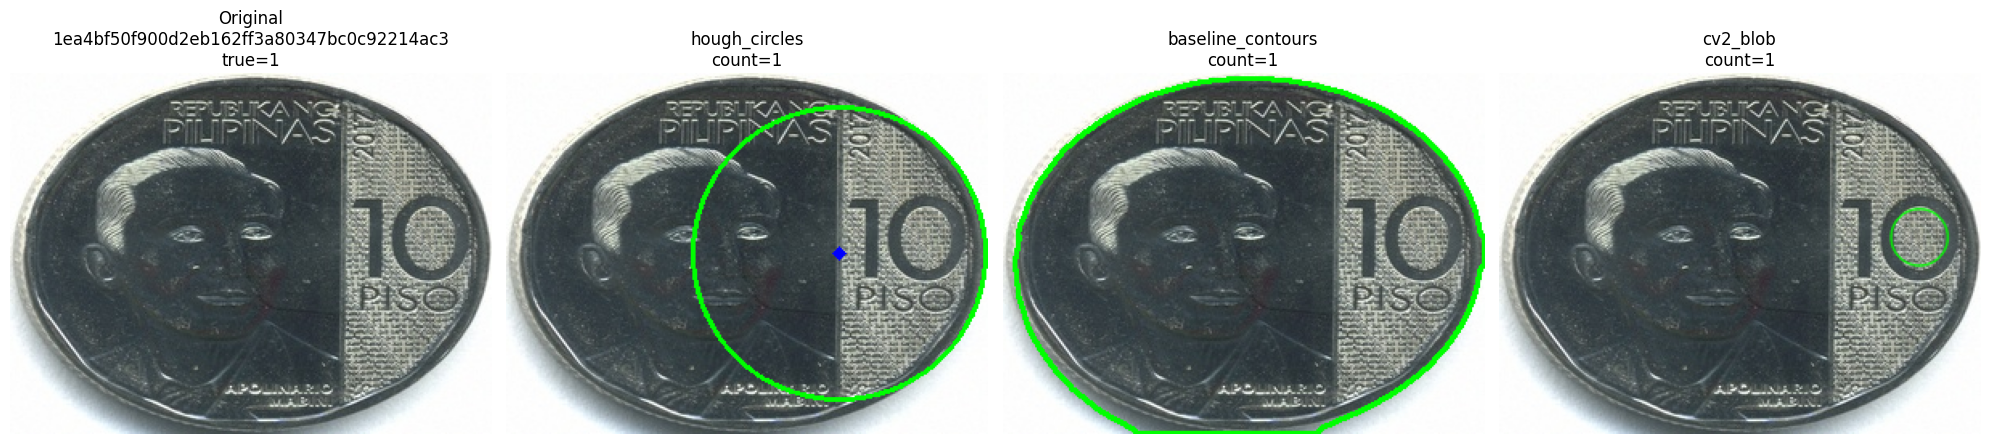

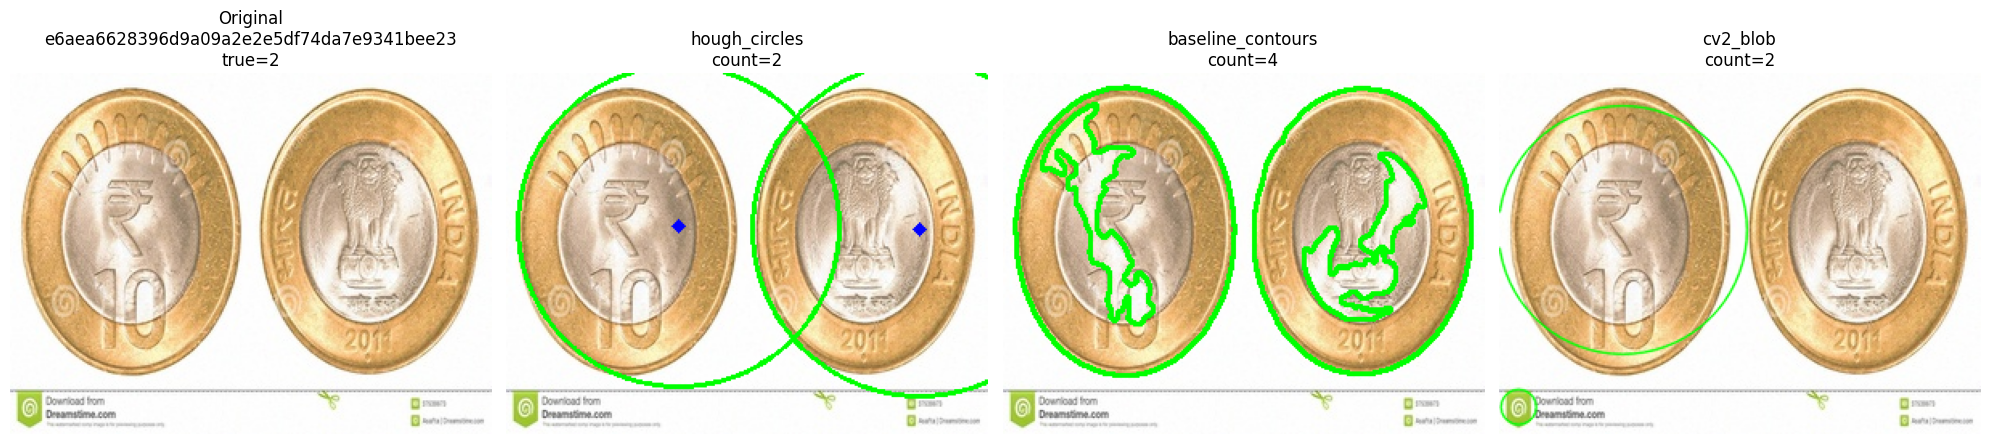

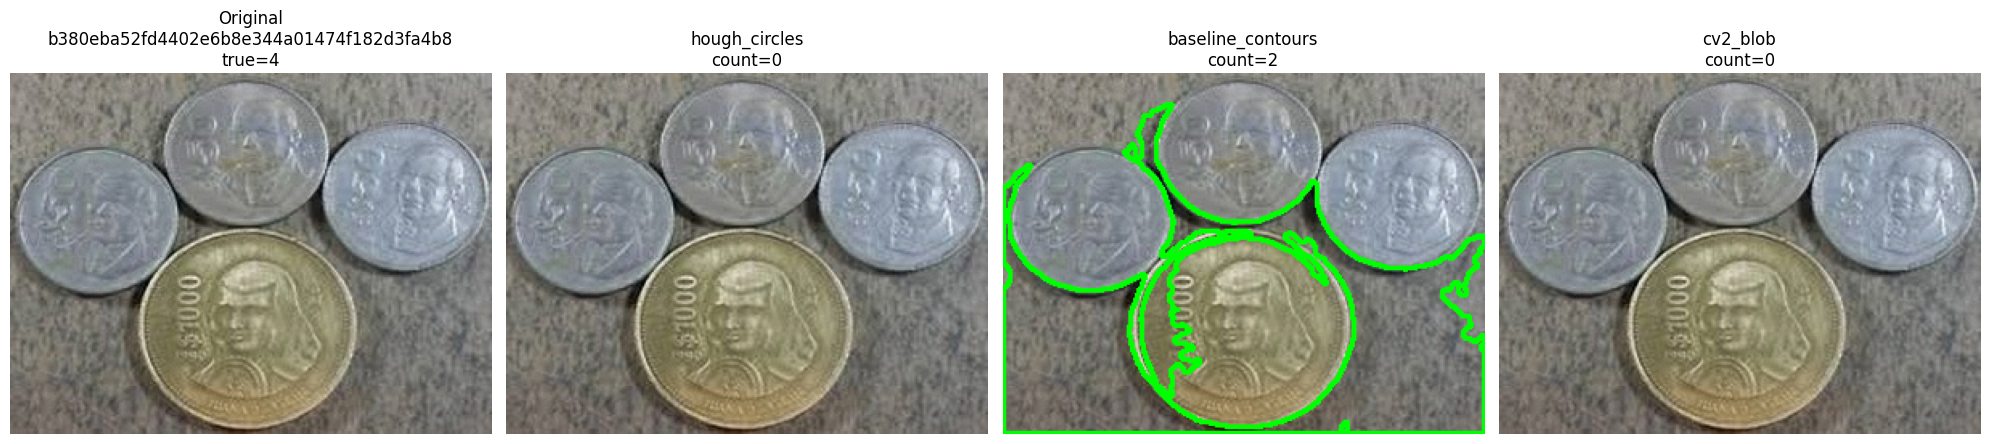

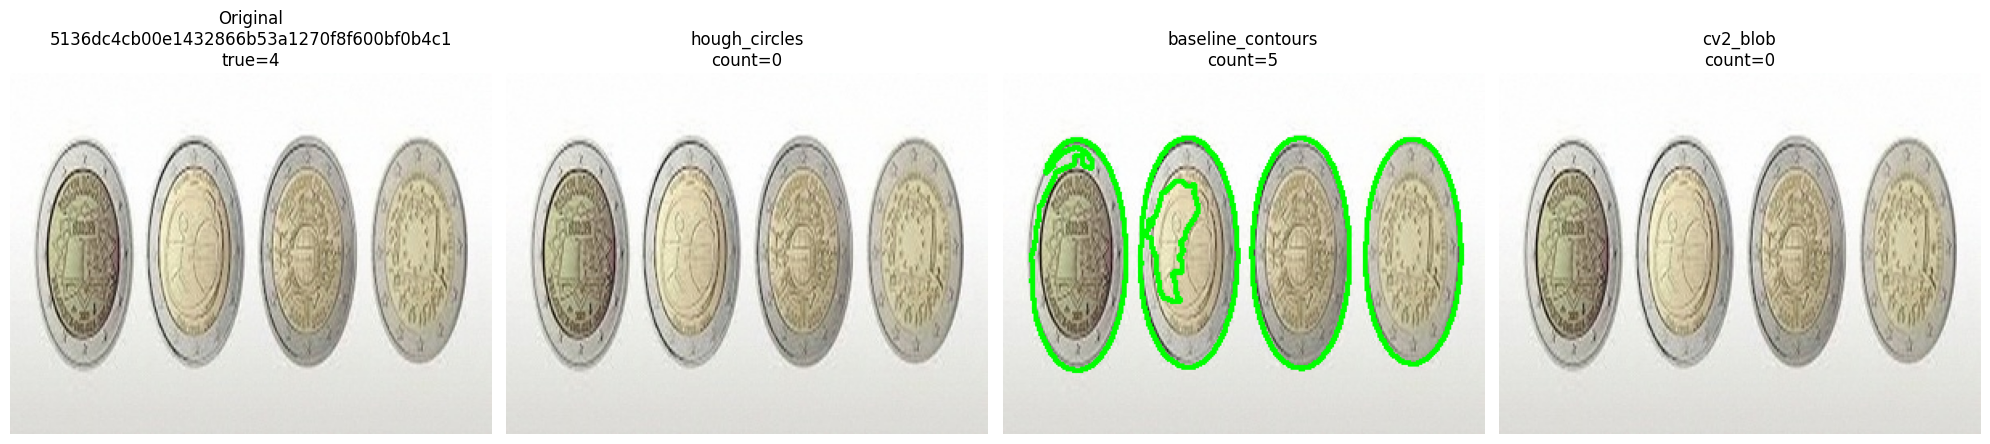

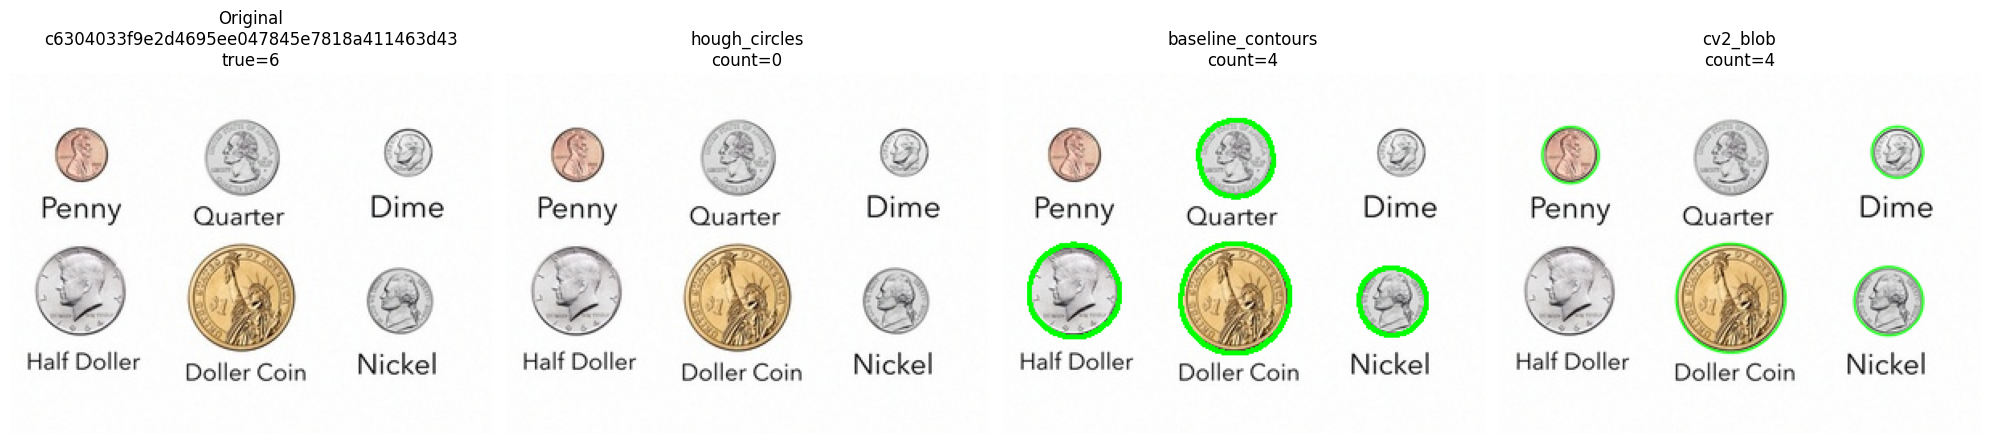

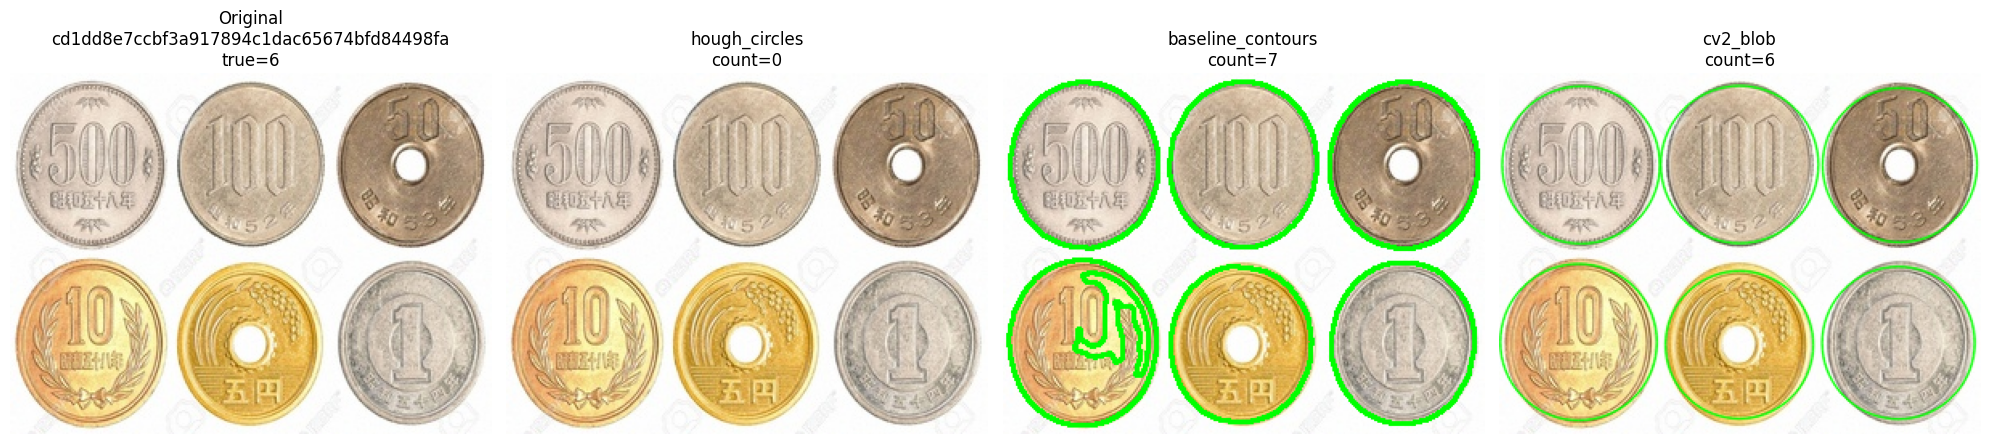

In [133]:
all_preds = run_in_loop(
    df=test_samples,
    images_dir=TRAIN_DIR,
    algorithms=algos,
    params_by_algorithm=params_map
)

### Hough Parameter Tuning 



#### Split data

In [137]:
def make_strat_bins(count_series):
    count_series = pd.Series(count_series).astype(float)
    binned = pd.cut(
        count_series,
        bins=[0, 1, 2, 4, 8, 16, np.inf],
        labels=["1", "2", "3-4", "5-8", "9-16", "17+"],
        include_lowest=True,
    )
    return binned.astype(str)

In [138]:
def split_train_val_no_leakage(df, val_size=0.2, seed=1488):
    df = df.copy().reset_index(drop=True)
    strat_bins = make_strat_bins(df["count"])

    use_stratify = strat_bins.value_counts().min() >= 2

    train_idx, val_idx = train_test_split(np.arange(len(df)), test_size=val_size, random_state=seed, stratify=strat_bins if use_stratify else None)

    train_df = df.iloc[train_idx].reset_index(drop=True)
    val_df = df.iloc[val_idx].reset_index(drop=True)
    return train_df, val_df

In [139]:
train_df, val_df = split_train_val_no_leakage(coins_df, val_size=0.2, seed=RANDOM_SEED)

In [141]:
train_df.describe(), val_df.describe()  

(            count
 count  578.000000
 mean     5.166090
 std      7.223836
 min      1.000000
 25%      1.000000
 50%      2.000000
 75%      6.000000
 max     96.000000,
             count
 count  145.000000
 mean     5.613793
 std      9.923447
 min      1.000000
 25%      1.000000
 50%      2.000000
 75%      6.000000
 max    102.000000)

### Tuning

In [161]:
def evaluate_params_on_df(df_eval, params, algorithm="cv2_blob"):
    y_true = df_eval["count"].to_numpy(dtype=float)
    y_pred = []

    for row in df_eval.itertuples(index=False):
        img_path = TRAIN_DIR / f"{row.image_id}.jpg"
        pred_count, _, _ = _run_algorithm_with_visuals(img_path, params=params, algorithm=algorithm)
        y_pred.append(pred_count)

    score = mcrmse(y_true, np.asarray(y_pred, dtype=float))
    return {"mcrmse": float(score), "n_samples": int(len(df_eval))}


In [ ]:
def tune_one_algorithm(train_df, base_params, grids, algorithm, num_worse=2):
    """
    Sequential tuning (1 param at a time) with early stop:
    якщо метрика погіршилась 2 рази підряд -> стоп по цьому параметру,
    фіксуємо найкраще значення і йдемо до наступного параметра.

    Inputs:
      train_df: DataFrame з колонками image_id, count
      base_params: dict стартових параметрів
      grids: dict, напр. {"min_area": [...], "max_area": [...]}
      algorithm: "baseline_contours" | "cv2_blob" | "hough_circles"

    Returns:
      best_params, best_score, history_df
    """
    best_params = dict(base_params)
    cache = {}
    history = []

    def score_params(params):
        key = tuple(sorted(params.items()))
        if key not in cache:
            cache[key] = evaluate_params_on_df(
                train_df,
                params=params,
                algorithm=algorithm
            )["mcrmse"]
        return cache[key]

    best_score = score_params(best_params)

    for param_name, values in grids.items():
        local_best_value = best_params.get(param_name, None)
        local_best_score = best_score
        worse_streak = 0

        for v in values:
            candidate = dict(best_params)
            candidate[param_name] = v

            score = score_params(candidate)

            history.append({
                "param": param_name,
                "value": v,
                "mcrmse": score,
                **candidate
            })

            if score < local_best_score:
                local_best_score = score
                local_best_value = v
                worse_streak = 0
            else:
                worse_streak += 1

            if worse_streak >= num_worse:
                break

        best_params[param_name] = local_best_value
        best_score = local_best_score

        print(f"{algorithm} | {param_name}: best={best_params[param_name]} | mcrmse={best_score:.6f}")

    history_df = pd.DataFrame(history).sort_values("mcrmse").reset_index(drop=True)
    return best_params, float(best_score), history_df


#### Tcontour

In [ ]:
grids = {
    "min_area": [50, 100, 150, 200, 400, 700, 1000, 1300, 1700, 2200],
    "max_area": [10000, 15000, 20000, 30000, 40000, 60000, 80000, 100000],
}

best_params_contour, best_score_contour, hist_contour = tune_one_algorithm(
    train_df=train_df,
    base_params={'min_area': 200.0, 'max_area': 10000.0},
    grids=grids,
    algorithm="baseline_contours",
)


baseline_contours | min_area: best=200.0 | mcrmse=5.436644
baseline_contours | max_area: best=10000.0 | mcrmse=5.436644


#### Tblob

In [ ]:
best_blob = {'min_area': 160,
 'max_area': 60000,
 'min_circularity': 0.28,
 'min_inertia_ratio': 0.15,
 'min_convexity': 0.82,
 'min_threshold': 5,
 'max_threshold': 250,
 'threshold_step': 8,
 'min_dist_between_blobs': 14,
 'filter_by_color': False,
 'blob_color': 0}


blob_grids = {
    "min_area": [100, 130, 160, 190, 220],
    "max_area": [45000, 55000, 60000, 65000, 75000],
    "min_circularity": [0.28, 0.32, 0.35, 0.38, 0.42],
    "min_inertia_ratio": [0.08, 0.11, 0.13, 0.15, 0.18],
    "min_convexity": [0.78, 0.82, 0.85, 0.88, 0.92],
    "min_threshold": [0, 3, 5, 8, 12],
    "max_threshold": [220, 235, 250, 255],
    "threshold_step": [6, 8, 10, 12, 14],
    "min_dist_between_blobs": [10, 12, 14, 16, 18],
    "filter_by_color": [False, True],
    "blob_color": [0],
}

best_params_blob, best_score_blob, hist_blob = tune_one_algorithm(
    train_df=train_df,
    base_params=best_blob,
    grids=blob_grids,
    algorithm="cv2_blob",
)

cv2_blob | min_area: best=160 | mcrmse=4.051357
cv2_blob | max_area: best=60000 | mcrmse=4.051357
cv2_blob | min_circularity: best=0.28 | mcrmse=4.051357
cv2_blob | min_inertia_ratio: best=0.15 | mcrmse=4.051357
cv2_blob | min_convexity: best=0.82 | mcrmse=4.051357
cv2_blob | min_threshold: best=5 | mcrmse=4.051357
cv2_blob | max_threshold: best=235 | mcrmse=4.046229
cv2_blob | threshold_step: best=8 | mcrmse=4.046229
cv2_blob | min_dist_between_blobs: best=14 | mcrmse=4.046229
cv2_blob | filter_by_color: best=False | mcrmse=4.046229
cv2_blob | blob_color: best=0 | mcrmse=4.046229


#### THough

In [174]:
hough_best = {'dp': 1.2, 'min_dist': 120, 'param1': 100, 'param2': 45, 'min_radius': 60, 'max_radius': 200, 'blur_ksize': 7, 'blur_sigma': 1.5}


hough_grids = {
    "dp": [1.0, 1.1, 1.2, 1.3, 1.4],
    "min_dist": [80, 100, 120, 140, 160],
    "param1": [80, 100, 120, 140],
    "param2": [35, 45, 55, 65],
    "min_radius": [40, 50, 60, 70, 80],
    "max_radius": [160, 180, 200, 220, 240],
    "blur_ksize": [5, 7, 9, 11],
    "blur_sigma": [1.0, 1.5, 2.0, 2.5],
}


best_params_hough, best_score_hough, hist_hough = tune_one_algorithm(
    train_df=train_df,
    base_params=hough_best,
    grids=hough_grids,
    algorithm="hough_circles",
)

hough_circles | dp: best=1.2 | mcrmse=8.087112
hough_circles | min_dist: best=80 | mcrmse=7.768047
hough_circles | param1: best=80 | mcrmse=7.454243
hough_circles | param2: best=35 | mcrmse=7.283317
hough_circles | min_radius: best=50 | mcrmse=7.215060
hough_circles | max_radius: best=160 | mcrmse=7.037099
hough_circles | blur_ksize: best=7 | mcrmse=7.037099
hough_circles | blur_sigma: best=1.5 | mcrmse=7.037099


In [175]:
algorithms_on_same_split = [
    {"name": "cv2_blob", "algorithm": "cv2_blob", "params": best_params_blob},
    {"name": "baseline_contours", "algorithm": "baseline_contours", "params": best_params_contour},
    {"name": "hough_circles", "algorithm": "hough_circles", "params": best_params_hough},
]

algorithms_on_same_split

[{'name': 'cv2_blob',
  'algorithm': 'cv2_blob',
  'params': {'min_area': 160,
   'max_area': 60000,
   'min_circularity': 0.28,
   'min_inertia_ratio': 0.15,
   'min_convexity': 0.82,
   'min_threshold': 5,
   'max_threshold': 235,
   'threshold_step': 8,
   'min_dist_between_blobs': 14,
   'filter_by_color': False,
   'blob_color': 0}},
 {'name': 'baseline_contours',
  'algorithm': 'baseline_contours',
  'params': {'min_area': 200.0, 'max_area': 10000.0}},
 {'name': 'hough_circles',
  'algorithm': 'hough_circles',
  'params': {'dp': 1.2,
   'min_dist': 80,
   'param1': 80,
   'param2': 35,
   'min_radius': 50,
   'max_radius': 160,
   'blur_ksize': 7,
   'blur_sigma': 1.5}}]

In [176]:
rows = []
for cfg in algorithms_on_same_split:
    full_data = evaluate_params_on_df(coins_df, params=cfg["params"], algorithm=cfg["algorithm"])

    train_eval = evaluate_params_on_df(train_df, params=cfg["params"], algorithm=cfg["algorithm"])
    val_eval = evaluate_params_on_df(val_df, params=cfg["params"], algorithm=cfg["algorithm"])

    rows.append({
        "name": cfg["name"],
        "algorithm": cfg["algorithm"],
        "full_data_mcrmse": float(full_data["mcrmse"]),
        "train_mcrmse": float(train_eval["mcrmse"]),
        "val_mcrmse": float(val_eval["mcrmse"]),
    })

same_split_results = pd.DataFrame(rows).sort_values("full_data_mcrmse").reset_index(drop=True)
display(same_split_results)


,name,algorithm,full_data_mcrmse,train_mcrmse,val_mcrmse
0,cv2_blob,cv2_blob,4.209914,4.046229,4.807322
1,baseline_contours,baseline_contours,6.588371,5.436644,9.930448
2,hough_circles,hough_circles,7.674210,7.037099,9.810972


# Feature Extraction


In [ ]:
def keypoints_to_features(keypoints, h, w):
    n = len(keypoints)
    feats = {}
    feats["n_blobs"] = n

    if n == 0:
        zero_cols = [
            "size_mean","size_std","size_min","size_max","size_median","size_sum",
            "area_mean","area_std","area_min","area_max","area_median","area_sum",
            "x_mean","x_std","y_mean","y_std","bbox_area","density"
        ]
        for c in zero_cols:
            feats[c] = 0.0
        return feats

    sizes = np.array([kp.size for kp in keypoints], dtype=np.float32)
    xs = np.array([kp.pt[0] for kp in keypoints], dtype=np.float32) / float(w)
    ys = np.array([kp.pt[1] for kp in keypoints], dtype=np.float32) / float(h)

    feats["size_mean"] = float(sizes.mean())
    feats["size_std"] = float(sizes.std())
    feats["size_min"] = float(sizes.min())
    feats["size_max"] = float(sizes.max())
    feats["size_median"] = float(np.median(sizes))
    feats["size_sum"] = float(sizes.sum())

    radii = sizes / 2.0
    areas = np.pi * (radii ** 2)

    feats["area_mean"] = float(areas.mean())
    feats["area_std"] = float(areas.std())
    feats["area_min"] = float(areas.min())
    feats["area_max"] = float(areas.max())
    feats["area_median"] = float(np.median(areas))
    feats["area_sum"] = float(areas.sum())

    feats["x_mean"] = float(xs.mean())
    feats["x_std"]  = float(xs.std())
    feats["y_mean"] = float(ys.mean())
    feats["y_std"]  = float(ys.std())

    minx, maxx = float(xs.min()), float(xs.max())
    miny, maxy = float(ys.min()), float(ys.max())
    bbox_area = max(0.0, (maxx - minx) * (maxy - miny))
    feats["bbox_area"] = float(bbox_area)
    feats["density"] = float(n / bbox_area) if bbox_area > 1e-9 else float(n)

    return feats

In [183]:
def extract_blob_features_from_path(image_path, **blob_kwargs):
    _, preprocessed_img, keypoints, pred_count, _ = detect_coins_blobs_with_preprocess_cv2(
        image_path=image_path,
        **blob_kwargs
    )

    h, w = preprocessed_img.shape[:2]
    feats = keypoints_to_features(keypoints, h, w)
    feats["pred_count"] = float(pred_count)

    return feats


In [184]:
def build_blob_feature_df(df, images_dir, **blob_kwargs):
    rows = []

    for _, r in df.iterrows():
        image_id = r["image_id"]
        image_path = f"{images_dir}/{image_id}.jpg"

        feats = extract_blob_features_from_path(image_path, **blob_kwargs)

        feats["image_id"] = image_id
        if "count" in r:
            feats["count"] = r["count"]

        rows.append(feats)

    return pd.DataFrame(rows)


In [185]:
blob_train_df = train_df.copy() 
blob_val_df = val_df.copy()

In [186]:
blob_best_feature = {'min_area': 160,
   'max_area': 60000,
   'min_circularity': 0.28,
   'min_inertia_ratio': 0.15,
   'min_convexity': 0.82,
   'min_threshold': 5,
   'max_threshold': 235,
   'threshold_step': 8,
   'min_dist_between_blobs': 14,
   'filter_by_color': False,
   'blob_color': 0}

blob_train_df = train_df.copy() 
blob_val_df = val_df.copy()

Xtr_df = build_blob_feature_df(blob_train_df, images_dir=TRAIN_DIR, **blob_best_feature)
Xval_df = build_blob_feature_df(blob_val_df, images_dir=TRAIN_DIR, **blob_best_feature)  


In [189]:
Xtr_df.describe().T

,count,mean,std,min,25%,50%,75%,max
n_blobs,578.0,4.967128,6.352769,0.0,1.000000,3.000000,6.000000,84.000000
size_mean,578.0,84.459605,67.638950,0.0,34.883325,63.338560,119.868011,300.122650
size_std,578.0,18.224078,26.045957,0.0,0.000000,7.670302,25.661000,123.062996
size_min,578.0,65.561184,72.813562,0.0,17.291602,26.358230,86.606081,300.122650
size_max,578.0,110.058187,74.007851,0.0,48.436953,94.050156,160.357399,300.122650
size_median,578.0,81.954079,70.218585,0.0,25.839334,59.120701,121.325813,300.122650
size_sum,578.0,283.053139,214.066230,0.0,141.513550,243.824860,365.880806,1662.151489
area_mean,578.0,9982.310729,13651.128265,0.0,1132.274689,3785.088135,13291.733398,70743.640625
area_std,578.0,2649.085525,5043.285027,0.0,0.000000,489.296494,2212.420654,27095.240234
area_min,578.0,7532.684054,13922.210601,0.0,234.833656,545.661469,5890.979004,70743.640625


In [227]:
Xval_df.describe().T

,count,mean,std,min,25%,50%,75%,max
n_blobs,145.0,5.303448,7.281373,0.0,1.000000,3.000000,7.000000,63.000000
size_mean,145.0,96.643845,73.122784,0.0,43.312515,67.656204,143.146332,255.343124
size_std,145.0,16.071133,25.614644,0.0,0.000000,5.480967,19.001062,114.133453
size_min,145.0,78.746902,81.666120,0.0,17.878815,33.321388,143.145462,255.343124
size_max,145.0,119.261595,75.380568,0.0,60.931679,93.499992,182.633148,279.293243
size_median,145.0,94.729968,75.323546,0.0,33.321388,65.217896,146.380554,255.343124
size_sum,145.0,303.873204,222.902127,0.0,172.121078,251.697617,379.659241,1268.269531
area_mean,145.0,12220.768463,15055.679848,0.0,1697.115234,4050.929443,17152.460938,51208.046875
area_std,145.0,2269.087692,4805.755119,0.0,0.000000,325.715759,1644.117310,23333.595703
area_min,145.0,10072.287371,15785.653793,0.0,251.054108,872.039368,16093.297852,51208.046875


In [231]:
def fit_eval_xgb(Xtr, ytr, Xva, yva, seed):
    model = XGBRegressor(
        n_estimators=2000,
        learning_rate=0.05,
        max_depth=4,
        min_child_weight=10,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=1.0,
        objective="reg:squarederror",
        eval_metric="rmse",
        random_state=seed,
        n_jobs=-1,
        early_stopping_rounds=100,
    )
    model.fit(Xtr, ytr, eval_set=[(Xva, yva)], verbose=False)

    pred = model.predict(Xva)
    pred = np.rint(np.clip(pred, 0, None))
    rmse_val = mcrmse(yva, pred)


    return rmse_val, model

In [228]:
y_tr = Xtr_df["count"]
y_va = Xval_df["count"]

base_drop = ["count", "image_id"] 
X_tr_base = Xtr_df.drop(columns=base_drop)
X_va_base = Xval_df.drop(columns=base_drop)

print("Base shapes:", X_tr_base.shape, X_va_base.shape)
print("Columns:", list(X_tr_base.columns))


Base shapes: (578, 20) (145, 20)
Columns: ['n_blobs', 'size_mean', 'size_std', 'size_min', 'size_max', 'size_median', 'size_sum', 'area_mean', 'area_std', 'area_min', 'area_max', 'area_median', 'area_sum', 'x_mean', 'x_std', 'y_mean', 'y_std', 'bbox_area', 'density', 'pred_count']


#### All features

In [233]:
cols_all = [c for c in X_tr_base.columns if c != "pred_count"]
rmse_all, m_all = fit_eval_xgb(X_tr_base[cols_all], y_tr, X_va_base[cols_all], y_va, RANDOM_SEED)
print("XGB all (no pred_count) RMSE:", rmse_all)


XGB all (no pred_count) RMSE: 5.794170673453057


#### No blob count

In [234]:
cols_no_blob = [c for c in X_tr_base.columns if c not in ["n_blobs", "pred_count"]]
rmse_no_blob, m_nb = fit_eval_xgb(X_tr_base[cols_no_blob], y_tr, X_va_base[cols_no_blob], y_va, RANDOM_SEED)
print("XGB no blob RMSE:", rmse_no_blob)


XGB no blob RMSE: 6.2134448216528115


#### Blob only

In [232]:
rmse_blob_only, m_b = fit_eval_xgb(X_tr_base[["n_blobs"]], y_tr, X_va_base[["n_blobs"]], y_va, RANDOM_SEED)
print("XGB only n_blobs RMSE:", rmse_blob_only)


XGB only n_blobs RMSE: 6.624406284391807


In [235]:
# booster = model_no_blob.get_booster()
# score = booster.get_score(importance_type="gain")

# importance_df = (
#     pd.DataFrame(score.items(), columns=["feature", "gain"])
#     .sort_values("gain", ascending=False)
# )

# print(importance_df)


In [ ]:
from sklearn.linear_model import Ridge

ridge = Ridge(alpha=1.0)
ridge.fit(X_tr_base[["n_blobs"]], y_tr)
pred = np.rint(np.clip(ridge.predict(X_va_base[["n_blobs"]]), 0, None))
rmse_ridge = mcrmse(y_va, pred)
print("Ridge only n_blobs RMSE:", rmse_ridge)


Ridge only n_blobs RMSE: 4.966091920768004


# Infer

In [236]:
test_df = pd.read_csv(TEST_CSV).copy()


blob_params = blob_best_feature

FACE_DEFAULT_COUNT = 0

pred_rows = []
for _, row in test_df.iterrows():
    image_id = row["image_id"]
    img_type = str(row.get("type", "coins")).strip().lower()

    if img_type == "coins":
        img_path = TEST_DIR / f"{image_id}.jpg"
        pred_count, _, _ = _run_algorithm_with_visuals(img_path, params=blob_params, algorithm="cv2_blob")
    else:
        pred_count = FACE_DEFAULT_COUNT

    pred_rows.append({"image_id": image_id, "count": int(pred_count)})

submission_blob_best = pd.DataFrame(pred_rows)
submission_blob_best.to_csv(PROJECT_ROOT / "submission_blob_best1.csv", index=False)

print("Coins rows:", int((test_df["type"].str.lower() == "coins").sum()))
print("Non-coins rows:", int((test_df["type"].str.lower() != "coins").sum()))
submission_blob_best


Saved: /home/tkharin/cs-ai220/assignment-1-classical-cv-algorithms-KharinTymofii/submission_blob_best1.csv
Shape: (3585, 2)
Coins rows: 721
Non-coins rows: 2864


,image_id,count
0,b6e281181c11269eaa1c11256c1582c5effec630,0
1,53189001e2ede913f9c1be729d7cabe0036746d3,20
2,aa8b264fd88180788a8dae046ead5bd6198005e6,0
3,705d7c1e06127ddb5d2905cc6806f0c544bc3387,0
4,459864ffbec10f5f863d52909a3e295b8c644a14,0
...,...,...
3580,3dab93d9890399d670e88009c23231c578aa2c8b,0
3581,2e092fe3fe9637d5adecebb176376a90d69eb625,0
3582,9143705c46dce87d18de90a5b4246544c639e199,13
3583,b948a478b0aae5df481aa228db7f5fa47f86197c,0


In [237]:
merge_test_df = pd.read_csv(TEST_CSV).copy()
merge_coins_df = pd.read_csv(PROJECT_ROOT / "submission_blob_best.csv").rename(columns={"count": "count_coins"})
merge_faces_df = pd.read_csv(PROJECT_ROOT / "submission.csv").rename(columns={"count": "count_faces"})

merged_submission_df = (
    merge_test_df
    .merge(merge_coins_df[["image_id", "count_coins"]], on="image_id", how="left")
    .merge(merge_faces_df[["image_id", "count_faces"]], on="image_id", how="left")
)

if merged_submission_df[["count_coins", "count_faces"]].isna().any().any():
    missing_rows = merged_submission_df[
        merged_submission_df["count_coins"].isna() | merged_submission_df["count_faces"].isna()
    ]
    raise ValueError(f"Missing predictions for {len(missing_rows)} rows")

merged_submission_df["count"] = np.where(
    merged_submission_df["type"].str.strip().str.lower() == "coins",
    merged_submission_df["count_coins"].astype(int),
    merged_submission_df["count_faces"].astype(int),
)

merged_submission = merged_submission_df[["image_id", "count"]]
merged_out_path = PROJECT_ROOT / "submission_merged2.csv"
merged_submission.to_csv(merged_out_path, index=False)
merged_submission.head()


,image_id,count
0,b6e281181c11269eaa1c11256c1582c5effec630,4
1,53189001e2ede913f9c1be729d7cabe0036746d3,20
2,aa8b264fd88180788a8dae046ead5bd6198005e6,3
3,705d7c1e06127ddb5d2905cc6806f0c544bc3387,4
4,459864ffbec10f5f863d52909a3e295b8c644a14,4
